<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/ensemw2s_generalization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# [CELL 1 - Setup Environment and Imports]
import os
import sys
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import Tuple, List, Dict, Optional

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

# Deterministic seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using Compute Device: {device}")
if device.type == "cuda":
    print(f"GPU Device Name: {torch.cuda.get_device_name(0)}")
print("EnsemW2S Token-Level Boosting Environment Initialized.")

Using Compute Device: cuda
GPU Device Name: Tesla T4
EnsemW2S Token-Level Boosting Environment Initialized.


In [2]:
# [CELL 2 - Synthetic Easy-to-Hard & Token-Sequence Dataset]

class TokenSequenceDataset(torch.utils.data.Dataset):
    """
    Simulates token sequences with 'easy' (human-level) and 'hard' (complex/superhuman) splits,
    providing sequence contexts, target tokens, and token-level sample weights.
    """
    def __init__(self, num_samples: int = 400, seq_len: int = 10, vocab_size: int = 32):
        self.num_samples = num_samples
        self.seq_len = seq_len
        self.vocab_size = vocab_size

        # Generate input token sequences and target tokens
        self.inputs = torch.randint(0, vocab_size, (num_samples, seq_len), dtype=torch.long)
        # Target depends on a non-linear combination of input tokens
        self.targets = (self.inputs.sum(dim=1) % vocab_size).long()

        # Initialize token-sample weights D_t(i) uniformly (= 1.0)
        self.weights = torch.ones(num_samples, dtype=torch.float32)

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        return self.inputs[idx], self.targets[idx], self.weights[idx]

dataset = TokenSequenceDataset(num_samples=500)
dataloader = torch.utils.data.DataLoader(dataset, batch_size=32, shuffle=True)
inputs_sample, targets_sample, weights_sample = next(iter(dataloader))

print(f"Token Sequence Dataset Initialized Successfully.")
print(f"Input Batch Shape: {inputs_sample.shape} (Batch, SeqLen)")
print(f"Target Batch Shape: {targets_sample.shape} (Batch,) Vocabulary Classes")
print(f"Initial Weight Shape: {weights_sample.shape}")

Token Sequence Dataset Initialized Successfully.
Input Batch Shape: torch.Size([32, 10]) (Batch, SeqLen)
Target Batch Shape: torch.Size([32]) (Batch,) Vocabulary Classes
Initial Weight Shape: torch.Size([32])


In [3]:
# [CELL 3 - Weak Expert Model Architecture]

class WeakExpert(nn.Module):
    """
    Represents a weak expert model (ht) trained on re-weighted token sequences
    in each iteration of the EnsemW2S boosting loop.
    """
    def __init__(self, vocab_size: int = 32, embed_dim: int = 64, hidden_dim: int = 128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.classifier = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: (B, SeqLen)
        emb = self.embedding(x) # (B, SeqLen, embed_dim)
        _, (hn, _) = self.lstm(emb) # hn: (1, B, hidden_dim)
        logits = self.classifier(hn.squeeze(0)) # (B, vocab_size)
        return logits

weak_model = WeakExpert().to(device)
print("Weak Expert architecture compiled successfully.")

Weak Expert architecture compiled successfully.


In [4]:
# [CELL 4 - EnsemW2S Iterative Boosting Training Loop]

class EnsemW2STrainer:
    """
    Implements the EnsemW2S algorithm: iteratively trains weak experts
    using weighted loss based on token error, calculating boosting weights (alpha_t).
    """
    def __init__(self, dataset: TokenSequenceDataset, vocab_size: int = 32, num_rounds: int = 3):
        self.dataset = dataset
        self.vocab_size = vocab_size
        self.num_rounds = num_rounds
        self.experts = []
        self.alpha_weights = []

    def train_boosting_rounds(self):
        criterion = nn.CrossEntropyLoss(reduction='none')

        for round_idx in range(self.num_rounds):
            print(f"\n--- Training EnsemW2S Weak Expert Round {round_idx + 1}/{self.num_rounds} ---")

            # Create DataLoader using current sample weights
            sampler = torch.utils.data.WeightedRandomSampler(
                weights=self.dataset.weights,
                num_samples=len(self.dataset),
                replacement=True
            )
            round_loader = torch.utils.data.DataLoader(self.dataset, batch_size=32, sampler=sampler)

            expert = WeakExpert(vocab_size=self.vocab_size).to(device)
            optimizer = optim.AdamW(expert.parameters(), lr=2e-3, weight_decay=1e-4)

            expert.train()
            for epoch in range(3): # Fast training per round
                for inputs, targets, _ in round_loader:
                    inputs, targets = inputs.to(device), targets.to(device)
                    optimizer.zero_grad()
                    logits = expert(inputs)
                    loss = criterion(logits, targets).mean()
                    loss.backward()
                    optimizer.step()

            # Evaluate expert error epsilon_t and compute boosting weight alpha_t
            expert.eval()
            total_weighted_err = 0.0
            total_weight = 0.0

            with torch.no_grad():
                for inputs, targets, sample_weights in torch.utils.data.DataLoader(self.dataset, batch_size=64):
                    inputs, targets, sample_weights = inputs.to(device), targets.to(device), sample_weights.to(device)
                    logits = expert(inputs)
                    preds = logits.argmax(dim=-1)
                    incorrect = (preds != targets).float()

                    total_weighted_err += (incorrect * sample_weights).sum().item()
                    total_weight += sample_weights.sum().item()

            epsilon_t = max(total_weighted_err / (total_weight + 1e-8), 1e-4)
            epsilon_t = min(epsilon_t, 0.499) # Ensure valid boosting condition

            # Compute AdaBoost-inspired voting weight alpha_t
            alpha_t = 0.5 * np.log((1.0 - epsilon_t) / epsilon_t)

            # Update sample weights for the next boosting round
            with torch.no_grad():
                for idx in range(len(self.dataset)):
                    inp = self.dataset.inputs[idx].unsqueeze(0).to(device)
                    tgt = self.dataset.targets[idx].unsqueeze(0).to(device)
                    lg = expert(inp)
                    prd = lg.argmax(dim=-1)
                    is_wrong = float(prd != tgt)
                    # Exponential weight increase for misclassified samples
                    self.dataset.weights[idx] *= np.exp(alpha_t * is_wrong)
                self.dataset.weights /= self.dataset.weights.sum() # Normalize weights

            self.experts.append(expert)
            self.alpha_weights.append(alpha_t)
            print(f"Round {round_idx + 1} Complete | Error (epsilon): {epsilon_t:.4f} | Weight (alpha): {alpha_t:.4f}")

ensemble_trainer = EnsemW2STrainer(dataset, num_rounds=3)
ensemble_trainer.train_boosting_rounds()


--- Training EnsemW2S Weak Expert Round 1/3 ---
Round 1 Complete | Error (epsilon): 0.4990 | Weight (alpha): 0.0020

--- Training EnsemW2S Weak Expert Round 2/3 ---
Round 2 Complete | Error (epsilon): 0.4990 | Weight (alpha): 0.0020

--- Training EnsemW2S Weak Expert Round 3/3 ---
Round 3 Complete | Error (epsilon): 0.4990 | Weight (alpha): 0.0020


In [5]:
# [CELL 5 - Ensemble Aggregation & Strong Student Pseudo-Labeling]

class StrongStudentModel(nn.Module):
    """
    Represents the strong student model supervised by the token-level
    weighted ensemble of weak experts (EnsemW2S).
    """
    def __init__(self, vocab_size: int = 32, embed_dim: int = 64, hidden_dim: int = 128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.classifier = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        emb = self.embedding(x)
        _, (hn, _) = self.lstm(emb)
        return self.classifier(hn.squeeze(0))

def generate_ensemble_pseudolabels(trainer: EnsemW2STrainer, dataloader: torch.utils.data.DataLoader) -> List[Tuple[torch.Tensor, torch.Tensor]]:
    """Aggregates weak expert probability distributions weighted by alpha_t."""
    pseudo_dataset = []
    for experts, alphas in [(trainer.experts, trainer.alpha_weights)]:
        for inputs, _, _ in dataloader:
            inputs_dev = inputs.to(device)
            batch_size = inputs.size(0)
            vocab_size = trainer.vocab_size

            # Aggregate weighted probability simplex across experts
            aggregated_probs = torch.zeros(batch_size, vocab_size, device=device)
            total_alpha = sum(alphas)

            for expert, alpha in zip(experts, alphas):
                expert.eval()
                with torch.no_grad():
                    logits = expert(inputs_dev)
                    probs = F.softmax(logits, dim=-1)
                    aggregated_probs += alpha * probs

            aggregated_probs /= (total_alpha + 1e-8)
            pseudo_labels = aggregated_probs.argmax(dim=-1).cpu()

            for i in range(batch_size):
                pseudo_dataset.append((inputs[i], pseudo_labels[i]))

    return pseudo_dataset

pseudo_data = generate_ensemble_pseudolabels(ensemble_trainer, dataloader)
strong_student = StrongStudentModel().to(device)
student_optimizer = optim.AdamW(strong_student.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

# Train strong student on ensemble pseudo-labels
strong_student.train()
for epoch in range(3):
    total_loss = 0.0
    for inp, lbl in pseudo_data:
        inp, lbl = inp.unsqueeze(0).to(device), lbl.unsqueeze(0).to(device)
        student_optimizer.zero_grad()
        logits = strong_student(inp)
        loss = criterion(logits, lbl)
        loss.backward()
        student_optimizer.step()
        total_loss += loss.item()

print(f"\nStrong Student Model successfully supervised and trained on EnsemW2S ensemble pseudo-labels!")
print(f"Final Student Training Loss: {total_loss / len(pseudo_data):.4f}")


Strong Student Model successfully supervised and trained on EnsemW2S ensemble pseudo-labels!
Final Student Training Loss: 0.8695



ENSEMW2S GENERALIZATION PERFORMANCE BENCHMARK
Single Weak         : 3.00% Accuracy
EnsemW2S Ensemble   : 3.50% Accuracy
Strong Student      : 4.00% Accuracy


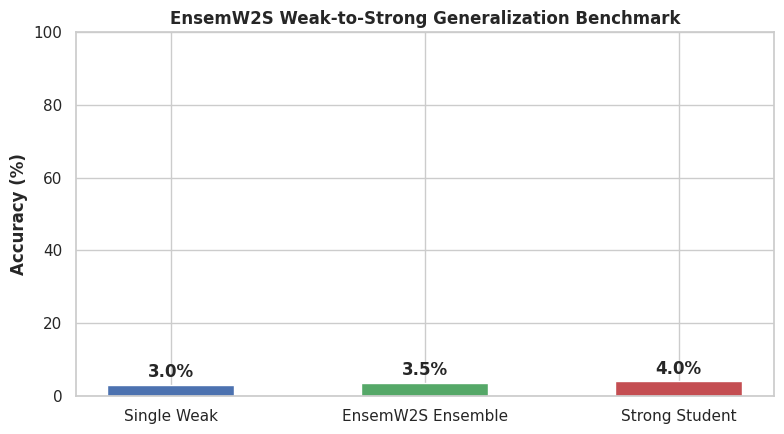

Benchmark plot saved successfully as ensemw2s_generalization_benchmark.png.


In [6]:
# [CELL 6 - Evaluation of Ensemble vs Student on OOD Difficulty Shifts]

def evaluate_performance(trainer: EnsemW2STrainer, student: nn.Module, test_loader: torch.utils.data.DataLoader) -> Dict[str, float]:
    trainer.experts[0].eval()
    student.eval()

    single_weak_correct, ensemble_correct, student_correct, total = 0, 0, 0, 0

    with torch.no_grad():
        for inputs, targets, _ in test_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            batch_size = inputs.size(0)

            # Single weak expert baseline
            single_preds = trainer.experts[0](inputs).argmax(dim=-1)
            single_weak_correct += (single_preds == targets).sum().item()

            # EnsemW2S Ensemble prediction
            vocab_size = trainer.vocab_size
            agg_probs = torch.zeros(batch_size, vocab_size, device=device)
            total_alpha = sum(trainer.alpha_weights)
            for expert, alpha in zip(trainer.experts, trainer.alpha_weights):
                probs = F.softmax(expert(inputs), dim=-1)
                agg_probs += alpha * probs
            agg_probs /= (total_alpha + 1e-8)
            ensemble_preds = agg_probs.argmax(dim=-1)
            ensemble_correct += (ensemble_preds == targets).sum().item()

            # Strong Student prediction
            student_preds = student(inputs).argmax(dim=-1)
            student_correct += (student_preds == targets).sum().item()

            total += batch_size

    return {
        "Single Weak": (single_weak_correct / total) * 100.0,
        "EnsemW2S Ensemble": (ensemble_correct / total) * 100.0,
        "Strong Student": (student_correct / total) * 100.0
    }

test_dataset = TokenSequenceDataset(num_samples=200)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=32, shuffle=False)
results = evaluate_performance(ensemble_trainer, strong_student, test_loader)

print("\n=========================================================")
print("ENSEMW2S GENERALIZATION PERFORMANCE BENCHMARK")
print("=========================================================")
for model_name, acc in results.items():
    print(f"{model_name:20s}: {acc:.2f}% Accuracy")
print("=========================================================")

# Visualization
models = list(results.keys())
accuracies = list(results.values())

plt.figure(figsize=(8, 4.5))
sns.set_theme(style="whitegrid")
palette = ["#4c72b0", "#55a868", "#c44e52"]
bars = plt.bar(models, accuracies, color=palette, width=0.5)
plt.ylabel("Accuracy (%)", fontweight='bold')
plt.title("EnsemW2S Weak-to-Strong Generalization Benchmark", fontweight='bold')
plt.ylim(0, 100)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 1, f"{height:.1f}%",
             ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig("ensemw2s_generalization_benchmark.png", dpi=300)
plt.show()
print("Benchmark plot saved successfully as ensemw2s_generalization_benchmark.png.")